# **Exercise 4 – Model Complexity (Width and Depth)**
*Group 74 : AI-ML Assessment 1*

**Introduction**

This exercise studies how the size of a CNN affects its performance on CIFAR-10. Two separate factors are investigated:

*   **Width** – the number of output channels (filters) in each convolutional layer.
*   **Depth** – the number of convolutional layers in the feature extractor.

Three width variations and three depth variations are trained. For each variation the validation accuracy, training loss and number of trainable parameters are recorded. The test set is not used in this exercise, so no width or depth is selected using test results.

All variations use the same CIFAR-10 data, 45,000/5,000 train/validation split, seed, batch size, optimiser, learning rate, weight decay and number of epochs as Exercises 2 and 3.

---

# Reusing the baseline preparation

The cells below are copied unchanged from the shared setup used in Notebooks 2 and 3, so the split and preprocessing are identical. The validation-index fingerprint printed below must match the other notebooks (`d45cf7fe22a123b42b27274bddc38a8e`).

# 1.Imports

In [1]:
import sys, time, random, hashlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import copy


import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset

# group settings
SEED        = 42
BATCH_SIZE  = 128
EPOCHS      = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 0.0
VAL_SIZE    = 5000            # from train set only
NUM_WORKERS = 0
DATA_DIR    = "./data"

# normalisation values
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

CLASS_NAMES = ["aeroplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"Device: {device}")

Python 3.13.16 | PyTorch 2.14.1+cu130 | torchvision 0.29.1+cu130
Device: cuda


In [2]:
import platform

def cpu_name():
    try:
        with open("/proc/cpuinfo") as f:
            for line in f:
                if "model name" in line:
                    return line.split(":")[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)
print("CPU:", cpu_name())
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Device: cuda
CPU: Intel(R) Xeon(R) CPU @ 2.00GHz
GPU: Tesla T4


# 2.Random seed setup

In [3]:
def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
print(f"Seed set to {SEED}")

Seed set to 42


# 3.CIFAR-10 Dataset Preparation and Train/Validation Split

In [4]:
# No augmentation here
base_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

train_transform = base_transform
eval_transform = base_transform

# Load data
full_train_for_train = datasets.CIFAR10(
    DATA_DIR,
    train=True,
    download=True,
    transform=train_transform
)

full_train_for_val = datasets.CIFAR10(
    DATA_DIR,
    train=True,
    download=True,
    transform=eval_transform
)

test_dataset = datasets.CIFAR10(
    DATA_DIR,
    train=False,
    download=True,
    transform=eval_transform
)

# 45k train / 5k validation split
split_generator = torch.Generator().manual_seed(SEED)

perm = torch.randperm(
    len(full_train_for_train),
    generator=split_generator
).numpy()

val_indices = np.sort(perm[:VAL_SIZE])
train_indices = np.sort(perm[VAL_SIZE:])

train_dataset = Subset(
    full_train_for_train,
    train_indices.tolist()
)

validation_dataset = Subset(
    full_train_for_val,
    val_indices.tolist()
)

# Same value everywhere = same split
split_hash = hashlib.md5(val_indices.tobytes()).hexdigest()

print(
    f"Split seed: {SEED} | "
    f"validation-index fingerprint (md5): {split_hash}"
)

100%|██████████| 170M/170M [17:01<00:00, 167kB/s]


Split seed: 42 | validation-index fingerprint (md5): d45cf7fe22a123b42b27274bddc38a8e


# 4.DataLoaders

In [5]:
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, worker_init_fn=seed_worker,
                          generator=loader_generator, pin_memory=(device.type == "cuda"))
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False,
                               num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

# 5.Dataset Sanity Checks

Train / Val / Test sizes: 45000 / 5000 / 10000
Batch shape: (128, 3, 32, 32) | label dtype: torch.int64
Per-channel batch mean (should be near 0): [-0.039 -0.037 -0.034]
Per-channel batch std  (should be near 1): [1.016 1.017 1.003]
All sanity checks passed.


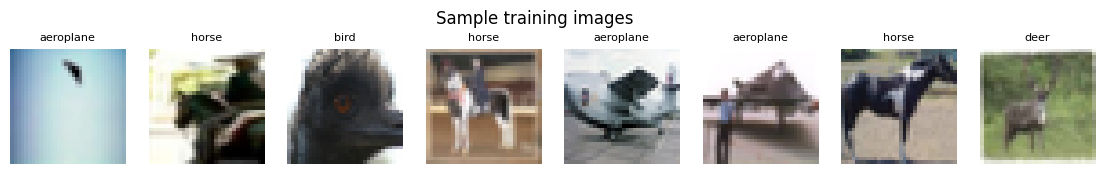

In [6]:
assert len(train_dataset) == 45000,      f"Train size is {len(train_dataset)}"
assert len(validation_dataset) == 5000,  f"Validation size is {len(validation_dataset)}"
assert len(test_dataset) == 10000,       f"Test size is {len(test_dataset)}"
assert len(set(train_indices) & set(val_indices)) == 0, "Train/validation overlap!"
assert len(train_indices) + len(val_indices) == 50000

images, labels = next(iter(train_loader))
assert images.shape == (BATCH_SIZE, 3, 32, 32), f"Unexpected batch shape {images.shape}"
assert labels.min() >= 0 and labels.max() <= 9, "Labels outside 0-9"
assert torch.isfinite(images).all(), "Non-finite pixel values"

print(f"Train / Val / Test sizes: {len(train_dataset)} / {len(validation_dataset)} / {len(test_dataset)}")
print(f"Batch shape: {tuple(images.shape)} | label dtype: {labels.dtype}")
print("Per-channel batch mean (should be near 0):", images.mean(dim=(0, 2, 3)).numpy().round(3))
print("Per-channel batch std  (should be near 1):", images.std(dim=(0, 2, 3)).numpy().round(3))
print("All sanity checks passed.")

mean_t = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
std_t  = torch.tensor(CIFAR_STD).view(3, 1, 1)
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for ax, img, lbl in zip(axes, images[:8], labels[:8]):
    ax.imshow((img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(CLASS_NAMES[lbl], fontsize=8)
    ax.axis("off")
plt.suptitle("Sample training images")
plt.show()

In [7]:
assert split_hash == "d45cf7fe22a123b42b27274bddc38a8e", "Split differs from the other notebooks!"
print("Split fingerprint matches Notebooks 2 and 3.")

Split fingerprint matches Notebooks 2 and 3.


# 6.Evaluation and training functions (same as Exercise 3)

In [8]:
def evaluate_model(model, data_loader, criterion):

    model.eval()

    total_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)

            correct_predictions += (
                predictions == labels
            ).sum().item()

            total_samples += batch_size

    average_loss = total_loss / total_samples

    accuracy = (
        correct_predictions / total_samples
    ) * 100

    return average_loss, accuracy

In [9]:
# Non-augmented training images
train_eval_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)
print("Training evaluation DataLoader created.")

Training evaluation DataLoader created.


In [10]:
def train_model(
    model,
    train_loader,
    train_eval_loader,
    validation_loader,
    epochs=EPOCHS
):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "validation_loss": [],
        "validation_accuracy": []
    }

    best_validation_accuracy = -1.0
    best_epoch = 0
    best_model_state = None

    start_time = time.perf_counter()

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            batch_size = labels.size(0)

            running_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)

            correct_predictions += (
                predictions == labels
            ).sum().item()

            total_samples += batch_size

        epoch_train_loss = running_loss / total_samples

        epoch_train_accuracy = (
            correct_predictions / total_samples
        ) * 100

        # evaluate training and validation performance
        train_eval_loss, train_eval_accuracy = evaluate_model(
            model,
            train_eval_loader,
            criterion
        )

        validation_loss, validation_accuracy = evaluate_model(
            model,
            validation_loader,
            criterion
        )

        history["train_loss"].append(train_eval_loss)
        history["train_accuracy"].append(train_eval_accuracy)
        history["validation_loss"].append(validation_loss)
        history["validation_accuracy"].append(validation_accuracy)

        # best checkpoint
        if validation_accuracy > best_validation_accuracy:

            best_validation_accuracy = validation_accuracy
            best_epoch = epoch + 1

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"| Train Loss: {train_eval_loss:.4f} "
            f"| Train Acc: {train_eval_accuracy:.2f}% "
            f"| Val Loss: {validation_loss:.4f} "
            f"| Val Acc: {validation_accuracy:.2f}%"
        )

    training_time = time.perf_counter() - start_time

    # restore validation checkpoint
    model.load_state_dict(best_model_state)

    print("\nTraining completed.")
    print("Best epoch:", best_epoch)
    print(
        f"Best validation accuracy: "
        f"{best_validation_accuracy:.2f}%"
    )
    print(f"Training time: {training_time:.2f} seconds")

    return model, history, best_epoch, training_time

# 7.Configurable CNN builder

`ConfigurableCNN` builds a CNN from a list of channel widths. Each entry adds one **convolution block** (3 × 3 convolution with padding 1, ReLU, 2 × 2 max-pooling), followed by a single fully connected layer to 10 classes.

*   Changing the **values** in the list changes the **width**.
*   Changing the **length** of the list changes the **depth**.

`ConfigurableCNN([32, 64])` has exactly the same layers and parameter count (60,362) as the Exercise 2 baseline CNN, so it is used as the medium variation. Pooling, ReLU and flattening have no trainable parameters.

In [11]:
class ConfigurableCNN(nn.Module):
    def __init__(self, channels, input_size=32, num_classes=10):
        super().__init__()

        self.channels = list(channels)

        # Convolutional layers
        self.convs = nn.ModuleList()
        in_channels = 3
        for out_channels in self.channels:
            self.convs.append(
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
            )
            in_channels = out_channels

        # Non-trainable operations
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.flatten = nn.Flatten()

        final_size = input_size // (2 ** len(self.channels))
        self.fc = nn.Linear(in_channels * final_size * final_size, num_classes)

    def forward(self, x):
        for conv in self.convs:
            x = self.pool(self.relu(conv(x)))
        x = self.flatten(x)
        return self.fc(x)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


assert count_parameters(ConfigurableCNN([32, 64])) == 60362, "Medium width does not match the baseline!"
print("ConfigurableCNN([32, 64]) matches the baseline CNN (60,362 parameters).")

ConfigurableCNN([32, 64]) matches the baseline CNN (60,362 parameters).


---

# Width Experiment

**Width** is defined as the number of output channels (filters) in each convolutional layer. The depth is fixed at **two convolutional layers** (the Exercise 2 baseline) and the number of channels is halved and doubled:

| Variation | Conv layer 1 channels | Conv layer 2 channels |
|---|---:|---:|
| Narrow | 16 | 32 |
| Medium (baseline) | 32 | 64 |
| Wide | 64 | 128 |

Only the channel numbers change. Every model is trained from scratch with the same seed and settings, and the checkpoint with the highest validation accuracy is kept.

# 1.Width architectures and parameter counts

In [12]:
width_configs = {
    "Narrow": [16, 32],
    "Medium": [32, 64],
    "Wide":   [64, 128],
}

for name, channels in width_configs.items():
    model = ConfigurableCNN(channels)
    print(f"--- {name} {channels} ---")
    print(model)
    print("Trainable parameters:", count_parameters(model), "\n")

--- Narrow [16, 32] ---
ConfigurableCNN(
  (convs): ModuleList(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Linear(in_features=2048, out_features=10, bias=True)
)
Trainable parameters: 25578 

--- Medium [32, 64] ---
ConfigurableCNN(
  (convs): ModuleList(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Linear(in_features=4096, out_features=10, bias=True)
)
Trainable parameters: 60362 

--- Wide [64, 128] ---
ConfigurableCNN(
  (convs): ModuleList(
    (0): Conv2d(3, 64

# 2.Training the width variations

In [13]:
width_histories = {}
width_rows = []

for name, channels in width_configs.items():
    print("=" * 70)
    print(f"Training {name} CNN | channels = {channels}")
    print("=" * 70)

    set_seed(SEED)

    width_generator = torch.Generator().manual_seed(SEED)
    width_train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        worker_init_fn=seed_worker,
        generator=width_generator,
        pin_memory=(device.type == "cuda")
    )

    model = ConfigurableCNN(channels).to(device)
    parameters = count_parameters(model)

    model, history, best_epoch, training_time = train_model(
        model=model,
        train_loader=width_train_loader,
        train_eval_loader=train_eval_loader,
        validation_loader=validation_loader,
        epochs=EPOCHS
    )

    width_histories[name] = history

    # Metrics at the best-validation checkpoint
    best_index = best_epoch - 1
    width_rows.append({
        "Experiment": "Width",
        "Variation": name,
        "Architecture": f"Conv {channels[0]} -> Conv {channels[1]} -> FC 10",
        "Trainable Parameters": parameters,
        "Best Epoch": best_epoch,
        "Best Validation Accuracy (%)": round(history["validation_accuracy"][best_index], 2),
        "Training Loss at Best Epoch": round(history["train_loss"][best_index], 4),
        "Training Accuracy at Best Epoch (%)": round(history["train_accuracy"][best_index], 2),
        "Validation Loss at Best Epoch": round(history["validation_loss"][best_index], 4),
        "Final Training Loss (epoch 20)": round(history["train_loss"][-1], 4),
        "Final Validation Accuracy (%)": round(history["validation_accuracy"][-1], 2),
        "Training Time (seconds)": round(training_time, 1),
    })

    torch.save(model.state_dict(), f"cnn_width_{name.lower()}_best_validation.pth")
    print()

Training Narrow CNN | channels = [16, 32]
Epoch [1/20] | Train Loss: 1.2327 | Train Acc: 56.83% | Val Loss: 1.2572 | Val Acc: 56.00%
Epoch [2/20] | Train Loss: 1.1111 | Train Acc: 61.66% | Val Loss: 1.1592 | Val Acc: 59.68%
Epoch [3/20] | Train Loss: 0.9798 | Train Acc: 66.10% | Val Loss: 1.0482 | Val Acc: 63.88%
Epoch [4/20] | Train Loss: 0.9245 | Train Acc: 68.16% | Val Loss: 1.0077 | Val Acc: 64.90%
Epoch [5/20] | Train Loss: 0.8654 | Train Acc: 70.26% | Val Loss: 0.9626 | Val Acc: 66.84%
Epoch [6/20] | Train Loss: 0.8436 | Train Acc: 70.86% | Val Loss: 0.9650 | Val Acc: 66.94%
Epoch [7/20] | Train Loss: 0.7942 | Train Acc: 72.82% | Val Loss: 0.9260 | Val Acc: 68.24%
Epoch [8/20] | Train Loss: 0.7758 | Train Acc: 73.12% | Val Loss: 0.9332 | Val Acc: 68.52%
Epoch [9/20] | Train Loss: 0.7594 | Train Acc: 74.05% | Val Loss: 0.9271 | Val Acc: 69.04%
Epoch [10/20] | Train Loss: 0.7430 | Train Acc: 74.14% | Val Loss: 0.9336 | Val Acc: 68.14%
Epoch [11/20] | Train Loss: 0.6968 | Train Acc:

# 3.Width results table

In [14]:
width_df = pd.DataFrame(width_rows)
width_df["Train-Validation Gap (pp)"] = (
    width_df["Training Accuracy at Best Epoch (%)"] - width_df["Best Validation Accuracy (%)"]
).round(2)

display(width_df)
width_df.to_csv("width_results.csv", index=False)
print("Saved width_results.csv")

,Experiment,Variation,Architecture,Trainable Parameters,Best Epoch,Best Validation Accuracy (%),Training Loss at Best Epoch,Training Accuracy at Best Epoch (%),Validation Loss at Best Epoch,Final Training Loss (epoch 20),Final Validation Accuracy (%),Training Time (seconds),Train-Validation Gap (pp)
0,Width,Narrow,Conv 16 -> Conv 32 -> FC 10,25578,13,70.40,0.6628,77.53,0.8919,0.5811,70.32,439.5,7.13
1,Width,Medium,Conv 32 -> Conv 64 -> FC 10,60362,7,72.42,0.5725,80.96,0.8353,0.2344,71.22,462.7,8.54
2,Width,Wide,Conv 64 -> Conv 128 -> FC 10,157578,9,73.70,0.3851,87.15,0.8518,0.1451,71.16,518.1,13.45


Saved width_results.csv


# 4.Width graphs

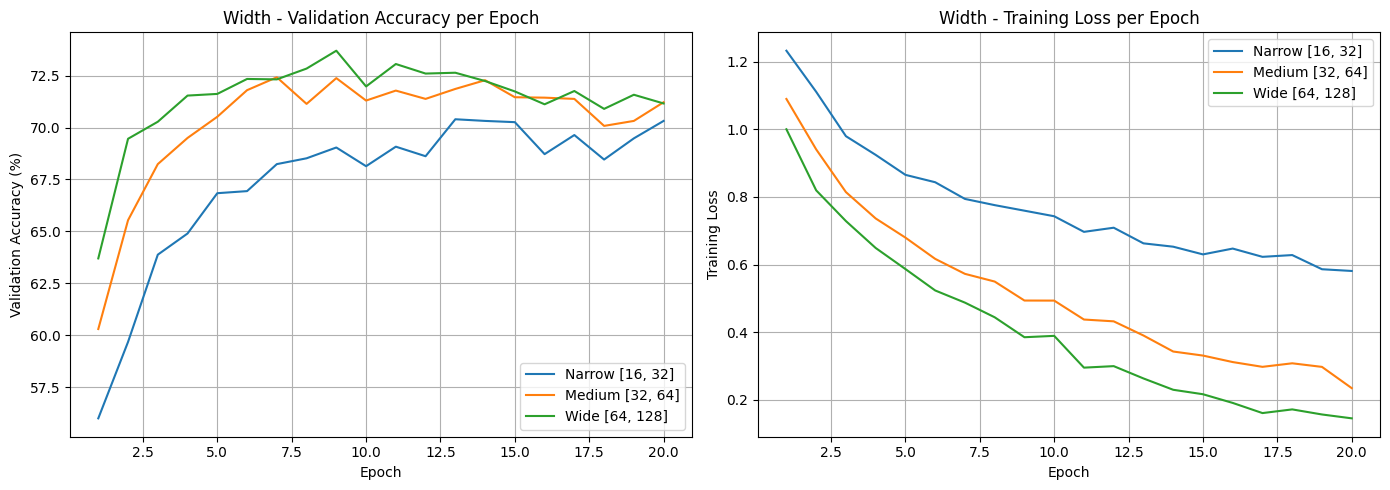

In [15]:
epochs_range = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, history in width_histories.items():
    label = f"{name} {width_configs[name]}"
    axes[0].plot(epochs_range, history["validation_accuracy"], label=label)
    axes[1].plot(epochs_range, history["train_loss"], label=label)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation Accuracy (%)")
axes[0].set_title("Width - Validation Accuracy per Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Training Loss")
axes[1].set_title("Width - Training Loss per Epoch")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("width_curves.png", dpi=300, bbox_inches="tight")
plt.show()

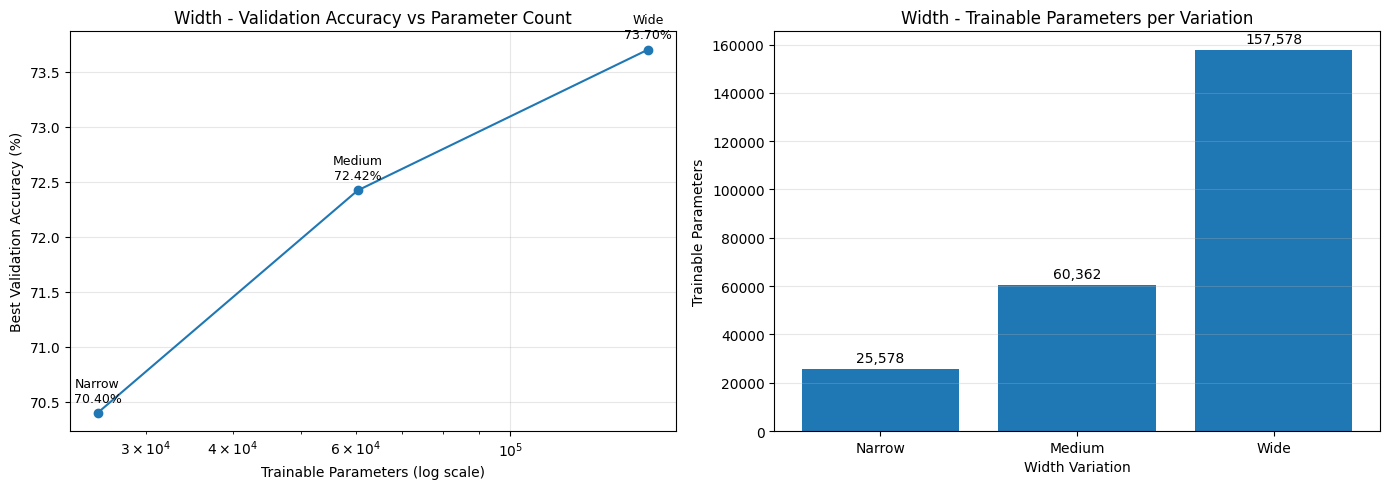

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

names = width_df["Variation"]
params = width_df["Trainable Parameters"]

# Best validation accuracy vs number of parameters
axes[0].plot(params, width_df["Best Validation Accuracy (%)"], marker="o")
for n, p, acc in zip(names, params, width_df["Best Validation Accuracy (%)"]):
    axes[0].annotate(f"{n}\n{acc:.2f}%", (p, acc), textcoords="offset points",
                     xytext=(0, 8), ha="center", fontsize=9)
axes[0].set_xscale("log")
axes[0].set_xlabel("Trainable Parameters (log scale)")
axes[0].set_ylabel("Best Validation Accuracy (%)")
axes[0].set_title("Width - Validation Accuracy vs Parameter Count")
axes[0].grid(True, alpha=0.3)

# Parameter count per variation
bars = axes[1].bar(names, params)
axes[1].bar_label(bars, labels=[f"{p:,}" for p in params], padding=3)
axes[1].set_xlabel("Width Variation")
axes[1].set_ylabel("Trainable Parameters")
axes[1].set_title("Width - Trainable Parameters per Variation")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("width_accuracy_vs_parameters.png", dpi=300, bbox_inches="tight")
plt.show()

# Width Experiment Results

In [17]:
print("WIDTH EXPERIMENT SUMMARY")
print("-" * 70)
for _, row in width_df.iterrows():
    print(f"{row['Variation']:<7} | params: {row['Trainable Parameters']:>7,} "
          f"| best val acc: {row['Best Validation Accuracy (%)']:.2f}% (epoch {row['Best Epoch']}) "
          f"| train loss: {row['Training Loss at Best Epoch']:.4f} "
          f"| gap: {row['Train-Validation Gap (pp)']:.2f} pp")

WIDTH EXPERIMENT SUMMARY
----------------------------------------------------------------------
Narrow  | params:  25,578 | best val acc: 70.40% (epoch 13) | train loss: 0.6628 | gap: 7.13 pp
Medium  | params:  60,362 | best val acc: 72.42% (epoch 7) | train loss: 0.5725 | gap: 8.54 pp
Wide    | params: 157,578 | best val acc: 73.70% (epoch 9) | train loss: 0.3851 | gap: 13.45 pp


**Discussion of width**

Increasing the number of filters increases the number of trainable parameters quickly, because the second convolution and the fully connected layer both grow with the channel count. More filters let each layer detect more distinct local patterns (edges, colours, textures), which gives the network more capacity to fit the training data.

The results table and graphs above show whether this extra capacity improved validation accuracy, whether the improvement levelled off, and whether the gap between training and validation accuracy grew (a sign of overfitting). These conclusions come from a single run with seed 42, so small differences should be interpreted with caution.

---

# Depth Experiment

*To be added: three depth variations built with `ConfigurableCNN` by changing the number of convolutional layers while keeping the channel width pattern fixed.*